**Query Parameters in FastAPI**

- Query parameters are request parameters attached to a URL after a question mark (?).
- They are used to filter or customize the data returned by an API.
- They follow a name-value pair relationship.
- The general syntax is: **URL?parameter_name=value**

For example : http://localhost:8000/books?category=math

Here:

- http://localhost:8000 → Base URL and port.
- /books → Path.
- ? → Indicates the beginning of query parameters.
- category → Query parameter name.
- math → Query parameter value.

**Implementing Query Parameters in FastAPI**

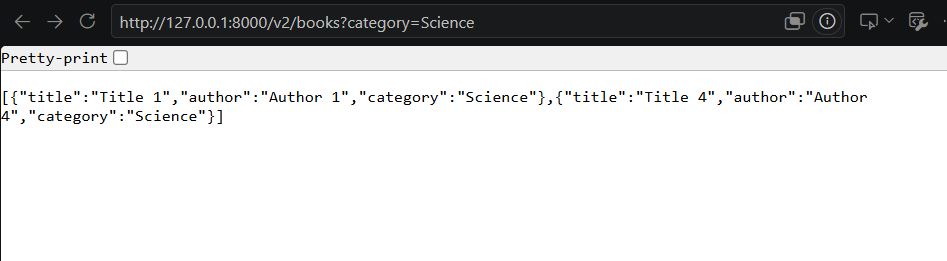

In [ ]:
'''Important: FastAPI automatically identifies category as a query parameter 
because it is not declared as a path parameter and is a simple type (str).'''
@app.get("/books")
def read_category_by_query(category: str):
    books_to_return = []

    for book in books:
        if book.get("category").casefold() == category.casefold():
            books_to_return.append(book)

    return books_to_return

**How does FastAPI identify the query parameter?**
Consider this request:
http://localhost:8000/books?category=science

And this function:
def read_category_by_query(category: str):

The parameter name in the URL must match the parameter name in the Python function.
Therefore, FastAPI automatically assigns: category = "science"

**Using Path Parameters and Query Parameters Together**

Query parameters can also be used along with path parameters in the same API request.

Consider this URL:
http://localhost:8000/books/author%20for?category=science [ USED % 20 IT IS INVISIBLE]

Here:

- /books → Path.
- /author%20for → Dynamic path parameter.
- %20 → URL encoding for a space.
- ?category=science → Query parameter.

We can interpret this request as:
Find books written by the author "author for" that belong to the science category.

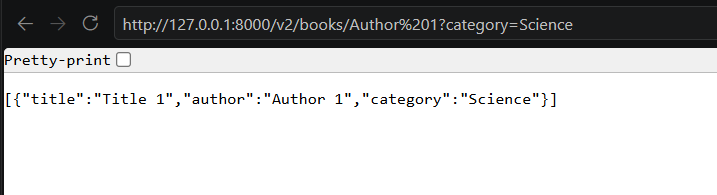

In [ ]:
"""FastAPI automatically assigns the values based on their names and locations.

book_author receives its value from the URL path.

category receives its value from the query string.
"""

@app.get("/books/{book_author}")
def read_author_category(
    book_author: str,
    category: str
):
    books_to_return = []

    for book in books:
        if (
            book.get("author").casefold() == book_author.casefold()
            and book.get("category").casefold() == category.casefold()
        ):
            books_to_return.append(book)

    return books_to_return


Important Points to Remember
- Query parameters are added after a question mark (?).
- Query parameters follow a name-value pair format.
- The format is ?name=value.
- Multiple query parameters can be separated using & --> /books?category=science&author=John
- FastAPI automatically reads query parameters based on function parameter names.
- Query parameters can be used together with path parameters.
- Query parameters are commonly used for filtering, searching, sorting, and pagination.

If someone sends a request without providing the query parameter category, 
FastAPI will return a 422 Unprocessable Entity error 
because category: str is required by default.

1. Example: Request WITH query parameter
http://localhost:8000/books/John?category=science

FastAPI receives:

- book_author = "John" (path parameter)
- category = "science" (query parameter)
- The function executes normally and returns matching books.

2. Example: Request WITHOUT query parameter

http://localhost:8000/books/John

FastAPI receives:

- book_author = "John"
- category = Missing
- 422 Unprocessable Entity
- FastAPI returns an error because the required category parameter was not provided.

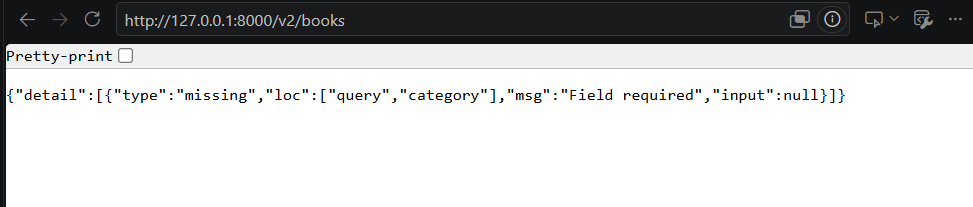

In [ ]:
##3. How to make the query parameter optional?

from typing import Optional

@app.get("/books/{book_author}")
def read_author_category(
    book_author: str,
    category: Optional[str] = None
):
    books_to_return = []

    for book in books:
        if book.get("author").casefold() == book_author.casefold():

            if category is None or book.get("category").casefold() == category.casefold():
                books_to_return.append(book)

    return books_to_return

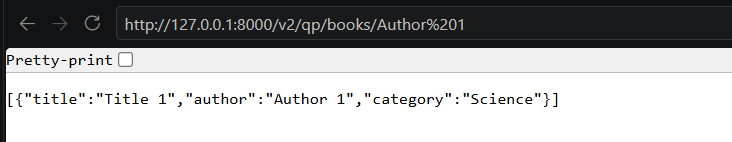

if 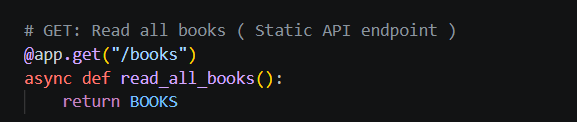 and 
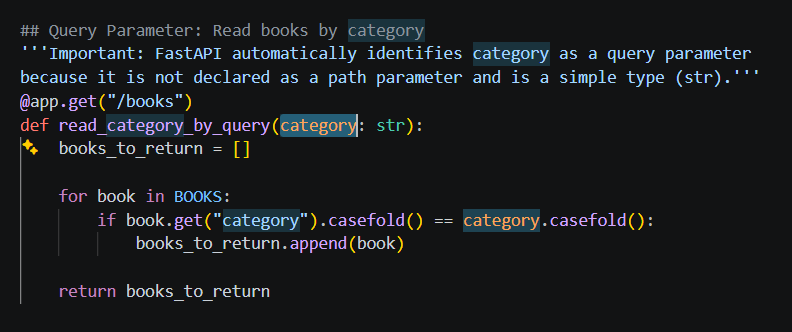 both are present fast api will take account of chronological order .